In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("wine_data.csv",header=None,usecols=[0,1,2])
df.columns=["class label","alcohol","malic acid"]

In [3]:
df.sample(5)

,class label,alcohol,malic acid
146,3,13.88,5.04
177,3,14.13,4.10
106,2,12.25,1.73
12,1,13.75,1.73
11,1,14.12,1.48


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   class label  178 non-null    int64  
 1   alcohol      178 non-null    float64
 2   malic acid   178 non-null    float64
dtypes: float64(2), int64(1)
memory usage: 4.3 KB


In [5]:
df.describe()

,class label,alcohol,malic acid
count,178.000000,178.000000,178.000000
mean,1.938202,13.000618,2.336348
std,0.775035,0.811827,1.117146
min,1.000000,11.030000,0.740000
25%,1.000000,12.362500,1.602500
50%,2.000000,13.050000,1.865000
75%,3.000000,13.677500,3.082500
max,3.000000,14.830000,5.800000


In [6]:
df.isnull().sum()

class label    0
alcohol        0
malic acid     0
dtype: int64

<Axes: xlabel='alcohol', ylabel='Density'>

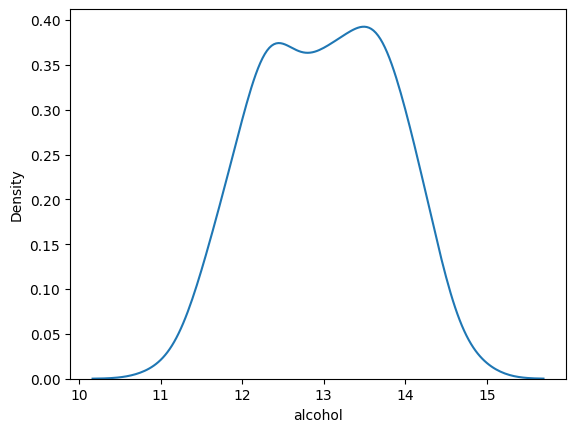

In [7]:
sns.kdeplot(df["alcohol"])

<Axes: xlabel='malic acid', ylabel='Density'>

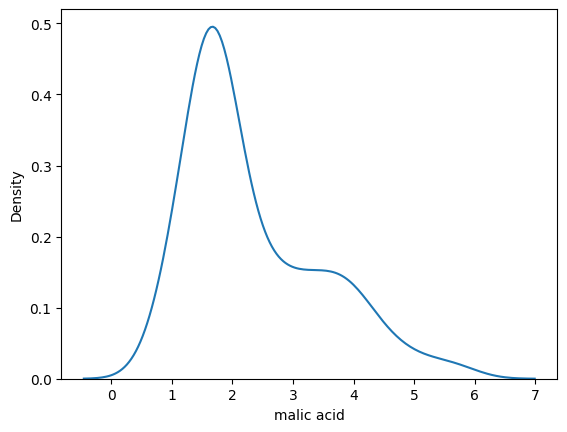

In [8]:
sns.kdeplot(df["malic acid"])

In [9]:
color_dict={1:"red",2:"blue",3:"green"}

<Axes: xlabel='alcohol', ylabel='malic acid'>

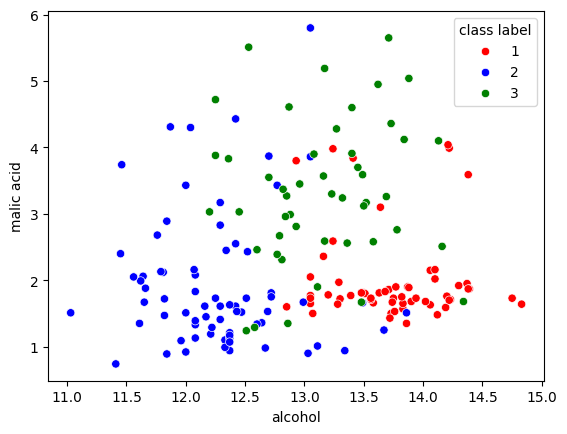

In [10]:
sns.scatterplot(x=df["alcohol"],y=df["malic acid"],hue=df["class label"],palette=color_dict)

In [11]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(
    df.drop("class label",axis=1),
    df['class label'],
    test_size=0.3,
    random_state=0
)

In [12]:
from sklearn.preprocessing import MinMaxScaler
scaler=MinMaxScaler()

### It fits the scaler to train the set,it will laern the parameters

In [13]:
scaler.fit(x_train)

,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False
Name,Type,Value
"data_max_ data_max_: ndarray of shape (n_features,)Per feature maximum seen in the data.. versionadded:: 0.17 *data_max_*","ndarray[float64](2,)","[14.75, 5.65]"
"data_min_ data_min_: ndarray of shape (n_features,)Per feature minimum seen in the data.. versionadded:: 0.17 *data_min_*","ndarray[float64](2,)","[11.03, 0.89]"
"data_range_ data_range_: ndarray of shape (n_features,)Per feature range ``(data_max_ - data_min_)`` seen in the data.. versionadded:: 0.17 *data_range_*","ndarray[float64](2,)","[3.72,4.76]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['alcohol','malic acid']"
"min_ min_: ndarray of shape (n_features,)Per feature adjustment for minimum. Equivalent to``min - X.min(axis=0) * self.scale_``","ndarray[float64](2,)","[-2.97,-0.19]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
"n_samples_seen_ n_samples_seen_: intThe number of samples processed by the estimator.It will be reset on new calls to fit, but increments across``partial_fit`` calls.",int,124


In [14]:
x_train_scaled=pd.DataFrame(scaler.transform(x_train),columns=x_train.columns)
x_test_scaled=pd.DataFrame(scaler.transform(x_test),columns=x_test.columns)

### This transforms the test and train data and converts it to dataframe because it transform in numpy array   

In [18]:
x_test_scaled.sample(5)

,alcohol,malic acid
35,0.543011,0.184874
37,0.446237,0.134454
6,0.814516,0.264706
28,0.196237,0.376050
14,0.685484,0.355042


In [16]:
np.round(x_train.describe(),1)

,alcohol,malic acid
count,124.0,124.0
mean,13.0,2.4
std,0.8,1.1
min,11.0,0.9
25%,12.4,1.6
50%,13.0,1.9
75%,13.6,3.2
max,14.8,5.6


In [36]:
np.round(x_train_scaled.describe(),1)

,alcohol,malic acid
count,124.0,124.0
mean,0.5,0.3
std,0.2,0.2
min,0.0,0.0
25%,0.4,0.2
50%,0.5,0.2
75%,0.7,0.5
max,1.0,1.0


Text(0.5, 1.0, 'After scaling')

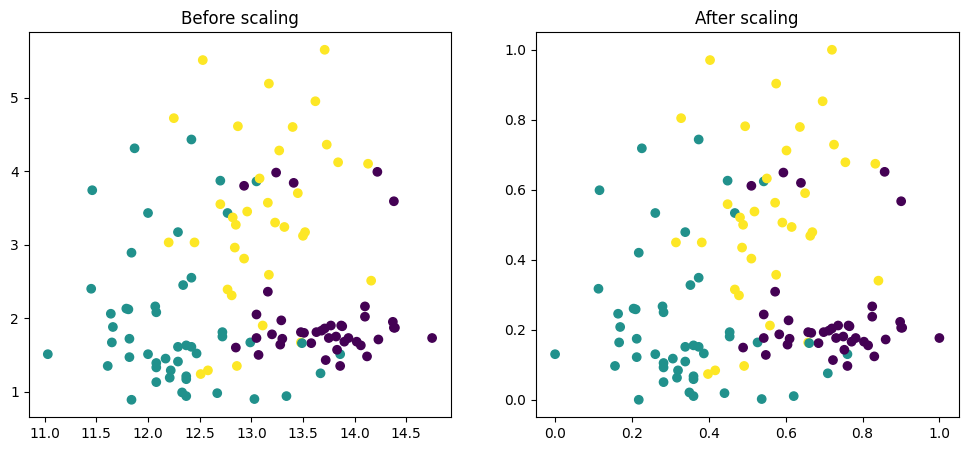

In [20]:
fig,(ax1,ax2) =plt.subplots(ncols=2,figsize=(12,5))
ax1.scatter(x=x_train["alcohol"],y=x_train["malic acid"],c=y_train)
ax1.set_title("Before scaling")
ax2.scatter(x=x_train_scaled["alcohol"],y=x_train_scaled["malic acid"],c=y_train)
ax2.set_title("After scaling")

### Now the above plot we can observe that there is no difference between before and after scaling only ranges are cahanged no effect on data

Text(0.5, 1.0, 'After scaling')

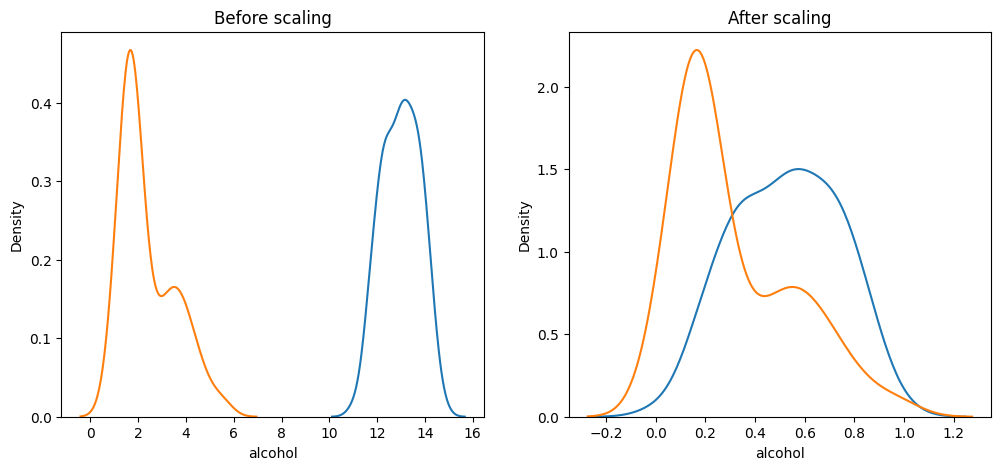

In [24]:
fig,(ax1,ax2) =plt.subplots(ncols=2,figsize=(12,5))
sns.kdeplot(x_train['alcohol'],ax=ax1)
sns.kdeplot(x_train['malic acid'],ax=ax1)
ax1.set_title("Before scaling")
sns.kdeplot(x_train_scaled['alcohol'],ax=ax2)
sns.kdeplot(x_train_scaled['malic acid'],ax=ax2)
ax2.set_title("After scaling")

### Now above kde plot we can observe that in before scaling we see the ranges are far apart but in after scaling we see thatthey both are in similar scale 

Text(0.5, 1.0, 'After scaling')

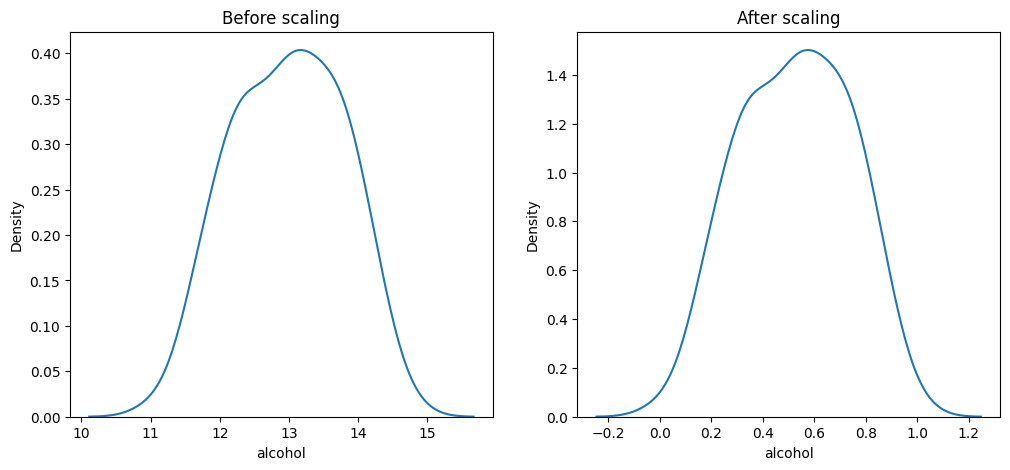

In [25]:
fig,(ax1,ax2) =plt.subplots(ncols=2,figsize=(12,5))
sns.kdeplot(x_train['alcohol'],ax=ax1)
ax1.set_title("Before scaling")
sns.kdeplot(x_train_scaled['alcohol'],ax=ax2)
ax2.set_title("After scaling")

Text(0.5, 1.0, 'After scaling')

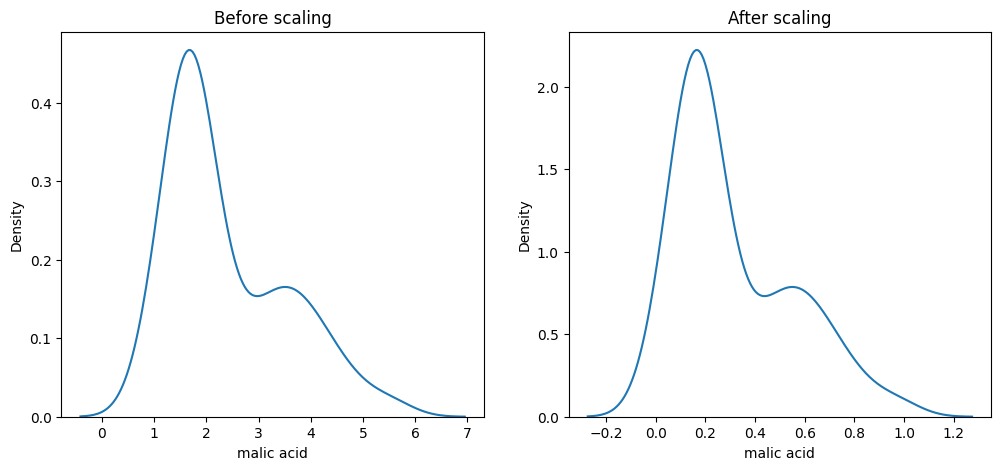

In [26]:
fig,(ax1,ax2) =plt.subplots(ncols=2,figsize=(12,5))
sns.kdeplot(x_train['malic acid'],ax=ax1)
ax1.set_title("Before scaling")
sns.kdeplot(x_train_scaled['malic acid'],ax=ax2)
ax2.set_title("After scaling")

### Now above both graph we see there no change in data in before and after scaling only ranges have changed